<a href="https://colab.research.google.com/github/oliviaberset/2026_solute_transport/blob/main/E5_geogenic_solutes_NAWA_Fracht.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Explore geogenic solute data: the NAWA-Fracht dataset

This exercise will focus on topics from Lesson 5, Geogenic Solutes, using a new dataset: "the National monitoring programme for substance load in swiss watercourses" (NAWA-Fracht) dataset. Two activities are proposed:

- Activity 1: Explore the range of average values of different geogenic elements in Swiss rivers
- Activity 2: Generate "mixing diagrams" for the Swiss rivers.

## The data

The “National monitoring programme for substance load in swiss watercourses” (NAWA-Fracht, previously known as NADUF) program has been collecting and publishing data about the chemical-physical state of about 30 Swiss rivers (see the map below).

The data are regularly published in the EAWAG Research Data Institutional Collection, under the [NAWA-Fracht project](https://doi.org/10.25678/00036W).
Extensive information about the data can be found directly in the readme.md file.

Note that some of the rivers included in the NAWA-Fracht program are also part of the CH-IRP dataset (stable water isotopes).

![NAWA-Fracht stations map](nawa-fracht_stations_map.jpg)

Data files provided for the exercise

- **NAWA-Fracht_data_14d.csv**: concentrations in a two-weekly rhythm (composite samples) with status and comments concerning reliability of sample and  chemical analysis

- **NAWA-Fracht_basin_properties.csv**: csv - file containing the names and coordinates of monitoring stations, mean river discharge, river length, basin area,  average altitude and land use.

The catchment properties were extracted from the file NAWA-Fracht_stations.kml. For ease of interpretation, only the basin properties that are relavant for this exercise have been reported. A column named 'key', with an abbreviation of the sampling station (see the following table), can be used to link the various datasets.

## Station Abbreviation

| Station Abbreviation | River           | Station                              |
|----------------------|-----------------|--------------------------------------|
| AN                   | Thur            | Andelfingen                          |
| AP                   | Sitter          | Appenzell                            |
| BA                   | Limmat          | Baden, Limmatpromenade               |
| BE                   | Aare            | Bern, Schönau                        |
| BR                   | Aare            | Brugg                                |
| CH                   | Rhone           | Chancy, Aux Ripes                    |
| DI, SC               | Rhein           | Diepoldsau, Rietbruecke/Schmitter    |
| EM, LI               | KleineEmme      | Emmen/Littau                         |
| ER                   | Alp             | Erlenbach                            |
| FR                   | Murg            | Frauenfeld                           |
| GE                   | Limmat          | Baden, Gebenstorf                    |
| GL                   | Glatt           | Rheinsfelden                         |
| GU                   | Saane           | Guemmenen                            |
| HA                   | Aare            | Hagneck                              |
| LA                   | Rhein           | Laufenburg                           |
| LU                   | Alp             | Luempenenbach                        |
| MA                   | Inn             | Martina                              |
| ME                   | Reuss           | Mellingen                            |
| MU                   | Birs            | Muenchenstein, Hofmatt               |
| NE                   | Sellenbodenbach | Neuenkirch                           |
| PO                   | Rhone           | PorteduScex                          |
| RE                   | Rhein           | Rekingen                             |
| RH                   | Rhein           | Rheinfelden                          |
| RI                   | Ticino          | Riazzino                             |
| SA                   | Inn             | Schanf                               |
| TH                   | Sense           | Thoerishaus, Sensematt               |
| VO                   | Alp             | Vogelbach                            |
| WJ, VI               | Rhein           | Weil, Palmrainbruecke/Village Neuf   |


## Units

This table reports the units for the data included in the NAWA-Fracht_basin_properties file.

| Column name                                                                                         | Unit                |
|:----------------------------------------------------------------------------------------------------|:---------------------|
| **station/key**                                                                                    | -                   |
| **longitude**                                                                                      | degree              |
| **latitude**                                                                                       | degree              |
| **station altitude**                                                                               | m                   |
| **mean discharge**                                                                                 | m³/s                |
| **river length**                                                                                   | km                  |
| **area**                                                                                           | km²                 |
| **average basin altitude**                                                                         | m                   |
| **intensive agriculture**                                                                          | %                   |
| **extensive agriculture**                                                                          | %                   |
| **closed forest**                                                                                  | %                   |
| **vegetation-free area**                                                                           | %                   |
| **remaining settlement area**                                                                      | %                   |



## Overview of the data

In [ ]:
# Load the main packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from aux_functions import add_geochem_shapes  # special function to make a fancier plot

In [ ]:
# Import the dataset nawa-fracht_data_14d into a Pandas DataFrame
data_path = os.path.join("data_for_exercise","nawa-fracht_csv","nawa-fracht_data_14d_2026-2.csv")
df = pd.read_csv(data_path,skiprows=[1],na_values=["NA","leer"])  # some missing values are indicated as "leer"
df = df.dropna(how="all").reset_index(drop=True)  # remove empty rows if any (sometimes it happens at the bottom of the file)
df["date_end"] = pd.to_datetime(df["date_end"], dayfirst=True)  # force the date to be a datetime object

# store the units in a separate variable (might be useful later)
with open(data_path) as f:
    header = f.readline().strip().split(',')   # line 1: variable names
    units = f.readline().strip().split(',')    # line 2: units

# show a list of the measured variables and their type
print("List of variables in df:")
print(df.columns)

# Import the NAWA-Fracht_basin_properties into a Pandas DataFrame, using the path already defined in activity 1
df_basin_prop = pd.read_csv(
    os.path.join("data_for_exercise","nawa-fracht_csv","NAWA-Fracht_basin_properties.csv"))

# Show the list of variables and their type for the basin properties
print("Variables and their type for df_basin_prop:")
print(df_basin_prop.dtypes)


List of variables in df:
Index(['station', 'status_number', 'remark', 'year', 'date_end', 'duration',
       'mean_discharge', 'total_discharge', 'temperature_BAFU', 'pH_BAFU',
       'conductivity_25C_BAFU', 'oxygen', 'oxygen_saturation', 'pH_lab',
       'conductivity_20C_lab', 'total_hardness', 'alkalinity', 'calcium',
       'magnesium', 'nitrate', 'total_nitrogen', 'DRP', 'total_phosphorus',
       'total_phosphorus_filtered', 'chloride', 'fluoride', 'bromide',
       'silicate', 'sulphate', 'sodium', 'potassium', 'iron', 'TOC', 'DOC',
       'suspended_material', 'chromium', 'zinc', 'copper', 'cadmium', 'lead',
       'nickel', 'mercury', 'barium', 'strontium', 'arsenic', 'manganese',
       'silver', 'cerium', 'lathanum', 'uranium', 'lithium', 'gadolinium',
       'NP', 'NP1EO', 'NP2EO', 'NP3EO'],
      dtype='object')
Variables and their type for df_basin_prop:
Name                          object
longitude                    float64
latitude                     float64
station

Now show some data. Note that (HCO₃⁻) concentration is not part of the dataset but we can easily compute it from alkalinity, because pH>6.5 almost always.

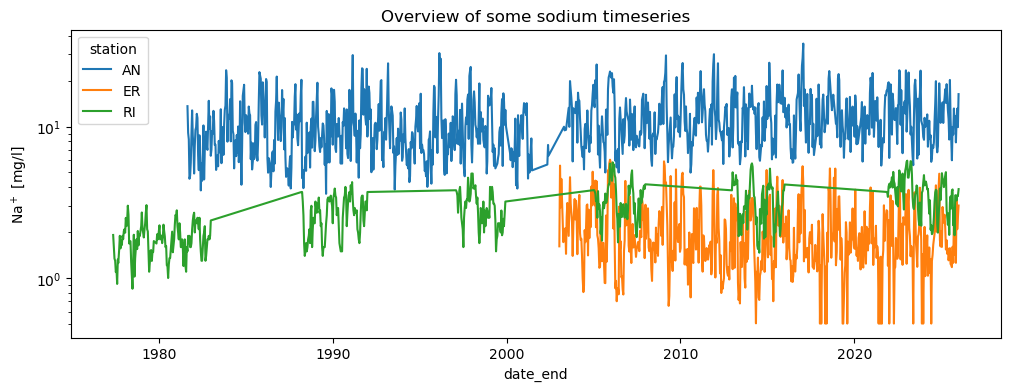

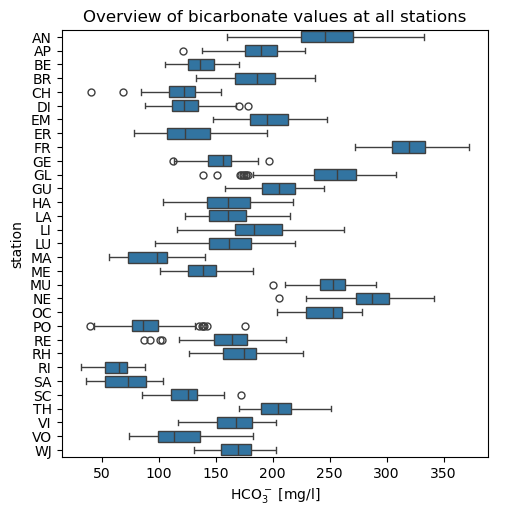

In [ ]:
# Compute bicarbonate concentration directly from alkalinity
mol_mass_HCO3 = 61 # g/mol
df["bicarbonate"] = df["alkalinity"]*mol_mass_HCO3  # convert meq/l to mg/l

# Select some variables of interest for the plots
var_sel = ['station','date_end','sodium','bicarbonate','mean_discharge']

# Show some timeseries of sodium concentration at each station
station_sel = ['AN','ER','RI']  # just a selection of stations to show
plt.figure(figsize=(12, 4))  # Long figure is better for long timeseries
sns.lineplot(
    data = df.loc[df["station"].isin(station_sel),var_sel],
    x = "date_end",
    y = "sodium",
    hue = "station",
)
plt.yscale("log")
plt.ylabel("Na$^+$ [mg/l]")
plt.title('Overview of some sodium timeseries')
plt.show()

# Show scatterplots with bicarbonate concentrations
sns.catplot(
    data = df[var_sel],
    kind = 'box',
    x = "bicarbonate",
    y = "station",
)
sns.despine(right=False, top=False)
plt.xlabel("HCO$_3^-$ [mg/l]")
plt.title('Overview of bicarbonate values at all stations')
plt.show()


We can see that elements concentrations vary substantially over space (as shown in the scatterplot) and over time (as shown in the timeseries) with typical annual cycles.

---

### Activity 1: Problem formulation

 It is useful to compute mean values for each element at each station. For this, you can use the `aggregate` function that we've seen in the previous exercises.

 - When looking at these average values, which sites have the highest and lowest concentrations of bicarbonate and silicate?
 - Does bicarbonate concentration correlate well with silicate concentration? Can you tell why?

---

### Activity 2: Problem formulation

The goal is to identify which lithologies are drained by the major Swiss rivers. The idea is to produce a plot similar to Gaillardet et al ([1999](https://doi.org/10.1016/S0009-2541(99)00031-5)), where bicarbonate, magnesium and calcium are normalized to sodium concentration:

![](1-s2.0-S0009254199000315-gr22_lrg.png)

### Activity 2: Some notes

- The mixing plot uses the **molar** ratios to sodium. So you need to use the mass/mol conversion for the elements involved in the plot:

| Solute         | Molar mass | Unit  |
|----------------|------------|-------|
| bicarbonate    | 61         | g/mol |
| calcium        | 40         | g/mol |
| sodium         | 22.99      | g/mol |
| magnesium      | 24.30      | g/mol |

- There are a lot of data points in the dataset. It is easier to focus only on the mean concentration of each element and use such a mean to compute the ratios.

- To make the plot more similar to the original one by Gaillardet et al., we have created a function `add_geochem_shapes` (requires the mpl_toolkits package). It will automatically set a log scale on both axis and adjust axis limits for optimal visualization. You can just call this function at the end of each subplot, with the syntax `add_geochem_shapes(ax, solute_type)`, where `ax` is the subplot that you want to transform and `solute_type` is either 'HCO3' or 'Mg'

```python
    # Example of how to use the function add_geochem_shapes
    fig,axs = plt.subplots(2,1,figsize=(6,8))  # prepare the axes
    axs[0].scatter(x,y)  # where x and y are the element ratios to plot
    add_geochem_shapes(axs[0], solute_type) # solute type is either 'HCO3' or 'Mg'
```